# 09 - Comparison of All Models

This notebook only **reads** the prediction files saved by notebooks 03-08 (`results/predictions/`). Nothing is trained here, so every model is scored with exactly the same code and test period.

We compare the five frameworks (XGBoost, Keras, fastai, TabNet, Lightning Flash) and the two baselines (Naive, Linear regression) on:
1. **Efficacy:** RMSE, MAE, R², skill vs naive, direction accuracy
2. **Simplicity:** lines of code, number of hyperparameters, training time, setup effort
3. **Transparency:** how well we can explain what the model does

Neural network results are the **average over 3 seeds**.

In [1]:
import sys
import json
import warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config, evaluate, plots

plots.setup()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

MODELS = ["Naive", "Linear", "XGBoost", "Keras", "fastai", "TabNet", "Flash"]
FRAMEWORKS = ["XGBoost", "Keras", "fastai", "TabNet", "Flash"]
TARGET_ORDER = ["1M", "5Y", "30Y"]

## 1. Load every prediction file and compute the metrics

In [2]:
rows = []
for file in sorted(config.PRED_DIR.glob("*.csv")):
    model, exp, seed = file.stem.split("_")
    pred = pd.read_csv(file, index_col=0, parse_dates=True)
    future = pred[[f"{t}_actual" for t in config.TARGETS]].set_axis(config.TARGETS, axis=1)
    today = pred[[f"{t}_today" for t in config.TARGETS]].set_axis(config.TARGETS, axis=1)
    pred_level = pred[[f"{t}_pred" for t in config.TARGETS]].values
    m = evaluate.evaluate(future, pred_level, today).reset_index()
    rows.append(m.assign(model=model, experiment=exp, seed=int(seed[4:])))
all_metrics = pd.concat(rows, ignore_index=True)
print(len(all_metrics) // 3, "prediction files loaded")

# average over seeds
metrics = all_metrics.groupby(["experiment", "model", "target"]).mean(numeric_only=True).drop(columns="seed")
seed_std = all_metrics.groupby(["experiment", "model", "target"])["skill_vs_naive"].std()
metrics.to_csv(config.RESULTS_DIR / "metrics_all.csv")

45 prediction files loaded


## 2. Results of the main experiment (C: change target, no raw yield levels)

RMSE and MAE are shown in **basis points** (1 bp = 0.01%) to make them easier to read.

In [3]:
def results_table(exp):
    table = metrics.loc[exp].copy()
    table[["RMSE", "MAE"]] = table[["RMSE", "MAE"]] * 100
    table = table.rename(columns={"RMSE": "RMSE (bp)", "MAE": "MAE (bp)"})
    table = table.reindex(pd.MultiIndex.from_product([MODELS, TARGET_ORDER], names=["model", "target"]))
    return table

table_c = results_table("C")
table_c.round(3)

RMSE (bp)  MAE (bp)     R2  R2_change  skill_vs_naive  direction_acc
model   target                                                                      
Naive   1M         14.683     6.158  0.956     -0.000           0.000            NaN
        5Y         13.790    10.498  0.840     -0.002           0.000            NaN
        30Y        11.108     8.664  0.932     -0.008           0.000            NaN
Linear  1M         14.994     7.407  0.954     -0.043          -0.021          0.573
        5Y         13.955    10.615  0.836     -0.026          -0.012          0.514
        30Y        11.524     9.162  0.927     -0.084          -0.037          0.487
XGBoost 1M         14.681     6.158  0.956      0.000           0.000          0.493
        5Y         13.998    10.751  0.835     -0.033          -0.015          0.513
        30Y        12.678     9.721  0.912     -0.313          -0.141          0.539
Keras   1M         15.764     7.107  0.949     -0.158          -0.074          0.531
        5Y         14.428    11.131  0.825     -0.099          -0.046          0.486
        30Y        12.486     9.917  0.913     -0.296          -0.124          0.481
fastai  1M         16.721     8.085  0.943     -0.299          -0.139          0.520
        5Y         14.457    11.023  0.824     -0.102          -0.048          0.492
        30Y        12.044     9.550  0.920     -0.185          -0.084          0.470
TabNet  1M         18.064     7.613  0.933     -0.515          -0.230          0.537
        5Y         14.273    10.868  0.829     -0.074          -0.035          0.512
        30Y        12.257     9.273  0.917     -0.228          -0.103          0.493
Flash   1M         17.498     7.417  0.937     -0.424          -0.192          0.520
        5Y         14.517    11.089  0.823     -0.111          -0.053          0.486
        30Y        12.203     9.578  0.918     -0.217          -0.099          0.477

Average over the three targets:

In [4]:
avg = {}
for exp in config.EXPERIMENTS:
    avg[exp] = results_table(exp).groupby(level="model", sort=False).mean()
avg_c = avg["C"]
avg_c.round(3)

,RMSE (bp),MAE (bp),R2,R2_change,skill_vs_naive,direction_acc
model,,,,,,
Naive,13.194,8.440,0.909,-0.003,0.000,NaN
Linear,13.491,9.062,0.906,-0.051,-0.024,0.525
XGBoost,13.786,8.877,0.901,-0.115,-0.052,0.515
Keras,14.226,9.385,0.896,-0.184,-0.081,0.499
fastai,14.407,9.553,0.896,-0.195,-0.090,0.494
TabNet,14.864,9.252,0.893,-0.272,-0.123,0.514
Flash,14.739,9.361,0.893,-0.251,-0.114,0.494


**Observations**
- **No model beats the naive forecast on average.** Average RMSE over the three targets: Naive 13.2 bp < Linear 13.5 < XGBoost 13.8 < Keras 14.2 < fastai 14.4 < Flash 14.7 < TabNet 14.9.
- The only positive skill is XGBoost for the 1M (+0.0001). That model is a single tree that predicts almost no change, so it's effectively the naive forecast.
- R² on levels is between 0.82 and 0.96 for **every** model, including naive, so it tells us nothing here. R² on the change is negative for every model.
- Direction accuracy is between 47% and 57%. The best is linear regression for the 1M (57%), which shows a small ability to call the direction of short-term rates (Fed policy moves in steps).
- **The simpler the model, the closer it gets to naive:** Linear (−0.02) and XGBoost (−0.05) do better than all four neural networks (−0.08 to −0.12).

## 3. All three experiments: skill vs naive

The heatmap shows `skill_vs_naive` for every model, experiment and target. 0 = as good as naive, positive (blue) = better than naive, negative (red) = worse. The colours are capped at ±0.3 so that small differences are still visible. The numbers are the real values.

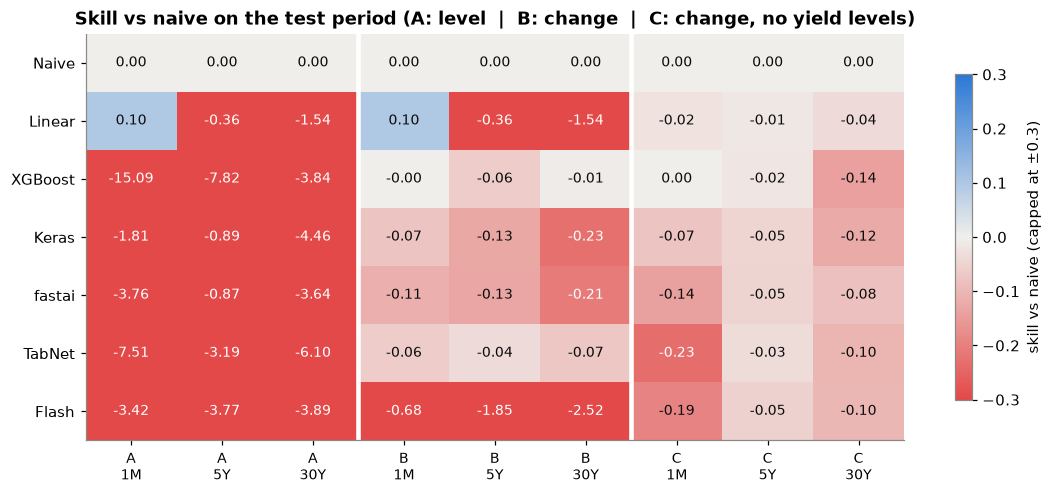

In [5]:
skill = metrics["skill_vs_naive"].unstack(["experiment", "target"])
skill = skill.reindex(index=MODELS, columns=pd.MultiIndex.from_product([["A", "B", "C"], TARGET_ORDER]))

fig, ax = plt.subplots(figsize=(12, 4.8))
im = ax.imshow(skill.values.clip(-0.3, 0.3), cmap=plots.DIVERGING.reversed(), vmin=-0.3, vmax=0.3, aspect="auto")
for i in range(skill.shape[0]):
    for j in range(skill.shape[1]):
        value = skill.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 0.2 else "#0b0b0b")
ax.set_xticks(range(skill.shape[1]))
ax.set_xticklabels([f"{e}\n{t}" for e, t in skill.columns], fontsize=9)
ax.set_yticks(range(len(MODELS)))
ax.set_yticklabels(MODELS)
for x in [2.5, 5.5]:
    ax.axvline(x, color="white", linewidth=3)
ax.grid(False)
ax.set_title("Skill vs naive on the test period (A: level  |  B: change  |  C: change, no yield levels)")
fig.colorbar(im, ax=ax, label="skill vs naive (capped at ±0.3)", shrink=0.8)
plots.save(fig, "09_skill_heatmap")
plt.show()

**Observations**
- **Experiment A** (left block) is red almost everywhere. Predicting the level fails for every learned model on the test period. XGBoost is the worst (skill −15 for the 1M) because trees can't extrapolate, and the neural networks fail too.
- For linear regression A and B are identical, as explained in notebook 03.
- In **experiment B**, XGBoost and TabNet are close to 0, but Flash fails (−0.7 to −2.5).
- In **experiment C** every model is in a narrow band between −0.23 and 0, the most consistent of the three experiments. C is the best experiment for Linear and Flash, and for the 5Y and 30Y with Keras and fastai. For XGBoost and TabNet, B and C are about equal.
- The RMSE chart shows the size of the effect: going from A to C cuts the error of every learned model by 1.5 to 10 times (XGBoost: 137 bp → 13.8 bp).

### Average RMSE per experiment

In [6]:
rmse_by_exp = pd.DataFrame({config.EXPERIMENT_NAMES[e]: avg[e]["RMSE (bp)"] for e in config.EXPERIMENTS})
rmse_by_exp.round(1)

,"A: level, all features","B: change, all features","C: change, no yield levels"
model,,,
Naive,13.2,13.2,13.2
Linear,20.1,20.1,13.5
XGBoost,137.2,13.5,13.8
Keras,42.6,15.0,14.2
fastai,49.1,15.1,14.4
TabNet,87.2,13.9,14.9
Flash,61.7,34.3,14.7


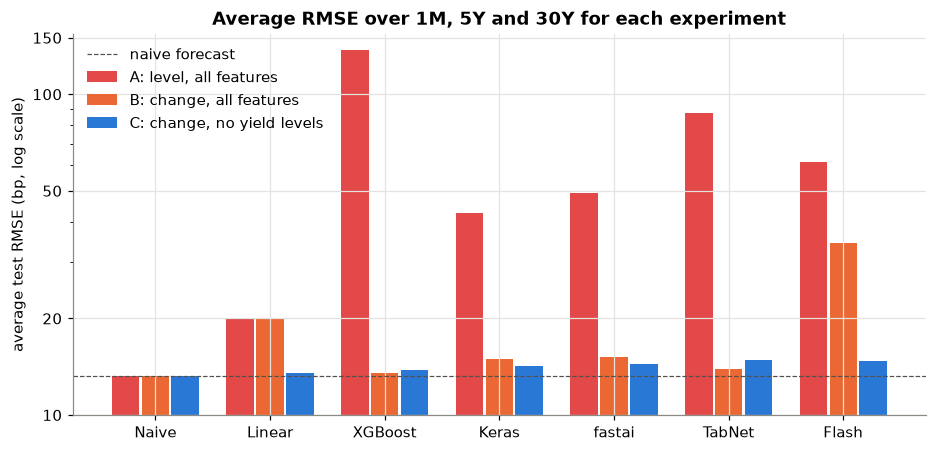

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(MODELS))
width = 0.26
for k, (exp, color) in enumerate(zip(config.EXPERIMENTS, [plots.RED, plots.ORANGE, plots.BLUE])):
    ax.bar(x + (k - 1) * width, avg[exp]["RMSE (bp)"], width=width - 0.02, color=color,
           label=config.EXPERIMENT_NAMES[exp])
ax.axhline(avg_c.loc["Naive", "RMSE (bp)"], color="#52514e", linestyle="--", linewidth=0.8,
           label="naive forecast")
ax.set_yscale("log")
ax.set_yticks([10, 20, 50, 100, 150])
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks(x)
ax.set_xticklabels(MODELS)
ax.set_ylabel("average test RMSE (bp, log scale)")
ax.set_title("Average RMSE over 1M, 5Y and 30Y for each experiment")
ax.legend()
plots.save(fig, "09_rmse_by_experiment")
plt.show()

## 4. Are the differences real? (Diebold-Mariano test)

The differences between models in experiment C are small, so we test whether each model's errors are **significantly** different from the naive forecast's errors. The Diebold-Mariano test compares the squared errors of two forecasts. Because our 5-day forecasts overlap, the variance is corrected for autocorrelation (Newey-West, 4 lags).

p < 0.05 means the difference from naive is statistically significant. The sign of the statistic says which model is better: negative = the model has smaller errors than naive.

In [8]:
def diebold_mariano(err_model, err_naive, lags=config.HORIZON - 1):
    d = err_model ** 2 - err_naive ** 2
    n = len(d)
    d_centered = d - d.mean()
    variance = np.sum(d_centered ** 2) / n
    for k in range(1, lags + 1):
        weight = 1 - k / (lags + 1)
        variance += 2 * weight * np.sum(d_centered[k:] * d_centered[:-k]) / n
    dm = d.mean() / np.sqrt(variance / n)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm)))
    return dm, p_value


naive = pd.read_csv(config.PRED_DIR / "Naive_C_seed42.csv", index_col=0)
dm_rows = []
for model in MODELS[1:]:
    pred = pd.read_csv(config.PRED_DIR / f"{model}_C_seed42.csv", index_col=0)
    for t in config.TARGETS:
        dm, p = diebold_mariano((pred[f"{t}_pred"] - pred[f"{t}_actual"]).values,
                                (naive[f"{t}_pred"] - naive[f"{t}_actual"]).values)
        dm_rows.append({"model": model, "target": config.TARGET_NAMES[t], "DM statistic": dm, "p-value": p,
                        "result": "better than naive" if (p < 0.05 and dm < 0) else
                                  "worse than naive" if (p < 0.05 and dm > 0) else "no significant difference"})
dm_table = pd.DataFrame(dm_rows).set_index(["model", "target"])
dm_table.round(3)

DM statistic  p-value                     result
model   target                                                  
Linear  1M             0.576    0.565  no significant difference
        5Y             1.323    0.186  no significant difference
        30Y            2.576    0.010           worse than naive
XGBoost 1M            -0.322    0.748  no significant difference
        5Y             1.384    0.166  no significant difference
        30Y            3.696    0.000           worse than naive
Keras   1M             0.736    0.462  no significant difference
        5Y             2.432    0.015           worse than naive
        30Y            1.060    0.289  no significant difference
fastai  1M             2.274    0.023           worse than naive
        5Y             2.365    0.018           worse than naive
        30Y            3.881    0.000           worse than naive
TabNet  1M             1.771    0.077  no significant difference
        5Y             1.942    0.052  no significant difference
        30Y            2.556    0.011           worse than naive
Flash   1M             1.882    0.060  no significant difference
        5Y             1.638    0.102  no significant difference
        30Y            3.134    0.002           worse than naive

**Observations**
- **None** of the 18 model-target pairs is significantly better than the naive forecast.
- 8 of the 18 are significantly **worse** (p < 0.05), mostly for the 30Y (5 of the 6 models). fastai is significantly worse for all three targets.
- Statistically, the best we can say is that linear regression and XGBoost (1M and 5Y), Keras (1M and 30Y), and TabNet and Flash (1M and 5Y) are **as good as** the naive forecast.

## 5. When do the models make their errors?

Rolling 60-day RMSE in the test period (experiment C, seed 42).

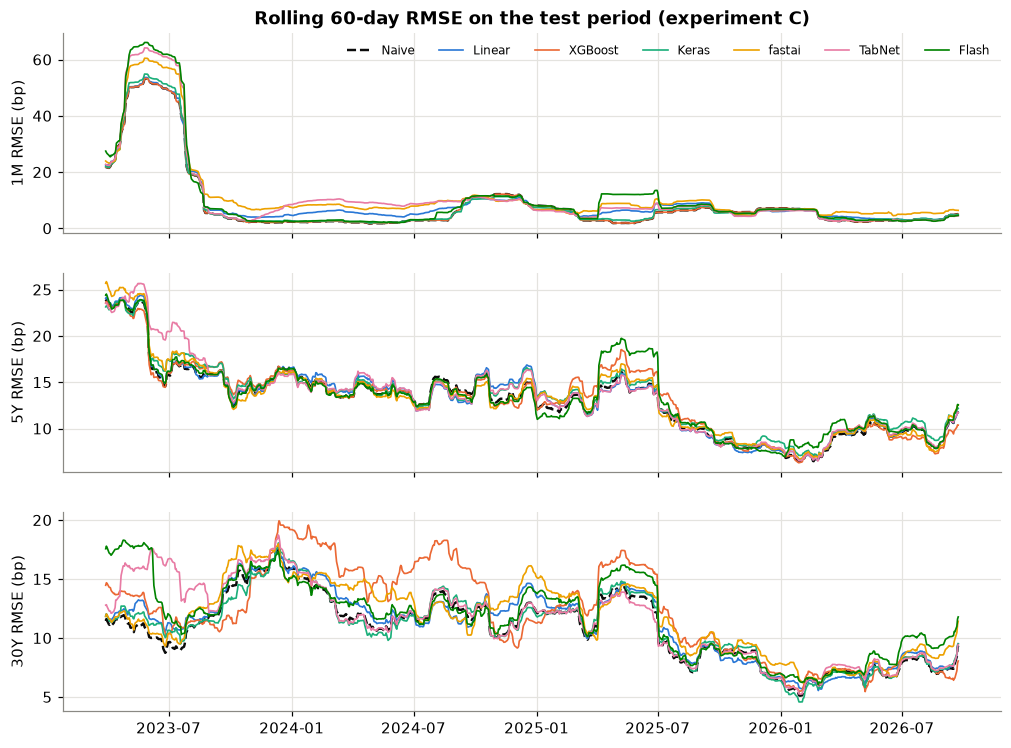

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, t in zip(axes, config.TARGETS):
    for model in MODELS:
        pred = pd.read_csv(config.PRED_DIR / f"{model}_C_seed42.csv", index_col=0, parse_dates=True)
        sq_err = (pred[f"{t}_pred"] - pred[f"{t}_actual"]) ** 2
        rolling = np.sqrt(sq_err.rolling(60).mean()) * 100
        style = {"color": "#0b0b0b", "linewidth": 1.6, "linestyle": "--"} if model == "Naive" else \
                {"color": plots.MODEL_COLORS[model], "linewidth": 1.1}
        ax.plot(rolling.index, rolling, label=model, **style)
    ax.set_ylabel(f"{config.TARGET_NAMES[t]} RMSE (bp)")
axes[0].legend(ncol=7, loc="upper right", fontsize=8)
axes[0].set_title("Rolling 60-day RMSE on the test period (experiment C)")
plots.save(fig, "09_rolling_rmse")
plt.show()

In [10]:
yearly_rows = []
for model in MODELS:
    pred = pd.read_csv(config.PRED_DIR / f"{model}_C_seed42.csv", index_col=0, parse_dates=True)
    for t in config.TARGETS:
        err = (pred[f"{t}_pred"] - pred[f"{t}_actual"]) * 100
        for year, e in err.groupby(err.index.year):
            yearly_rows.append({"model": model, "target": config.TARGET_NAMES[t], "year": year,
                                "RMSE (bp)": np.sqrt((e ** 2).mean())})
yearly = pd.DataFrame(yearly_rows).pivot_table(index=["target", "model"], columns="year", values="RMSE (bp)")
yearly.reindex(pd.MultiIndex.from_product([TARGET_ORDER, MODELS])).round(1)

year         2023  2024  2025  2026
1M  Naive    26.7   7.0   5.5   3.7
    Linear   27.0   7.4   6.5   4.1
    XGBoost  26.7   7.0   5.5   3.7
    Keras    27.5   6.5   5.6   3.9
    fastai   31.1   8.6   7.6   5.8
    TabNet   32.3   9.1   6.5   3.4
    Flash    33.3   7.2   8.2   3.7
5Y  Naive    17.9  13.8  11.1  10.2
    Linear   18.1  14.2  10.9  10.3
    XGBoost  18.0  13.7  12.2   9.7
    Keras    18.1  14.1  11.5  10.7
    fastai   18.8  13.7  11.5  10.5
    TabNet   18.9  14.2  11.0  10.4
    Flash    18.2  13.5  12.5  11.1
30Y Naive    13.0  12.0   9.9   8.1
    Linear   13.6  12.7  10.1   8.1
    XGBoost  14.4  14.6  11.7   7.8
    Keras    13.2  11.9  10.2   8.2
    fastai   13.6  13.8  10.6   9.0
    TabNet   15.2  12.1   9.8   8.3
    Flash    15.0  12.7  10.7   9.5

**Observations**
- The errors are largest in **spring 2023**. The rolling 1M RMSE goes above 50-65 bp during the March 2023 banking stress (Silicon Valley Bank) and the May 2023 debt-ceiling standoff, when the 1M yield jumped to 6.02%. Every model, including naive, missed these shocks.
- By year, the 1M RMSE falls from about 27 bp in 2023 to about 4 bp in 2026 as markets calmed down. The 5Y falls from about 18 bp to about 10 bp.
- The differences between models are small compared with how much the error changes over time. **The market environment matters more than the choice of model.**
- XGBoost's 30Y model had a bad period in late 2023-2024 (rolling RMSE up to about 19 bp). This is the overfitted model chosen on the validation set.

## 6. Stability across random seeds

Standard deviation of `skill_vs_naive` across the 3 seeds (experiment C). Naive, Linear and XGBoost give the same result every time.

In [11]:
seed_std.loc["C"].unstack("target").reindex(index=["Keras", "fastai", "TabNet", "Flash"], columns=TARGET_ORDER).round(3)

target,1M,5Y,30Y
model,,,
Keras,0.088,0.048,0.186
fastai,0.050,0.018,0.007
TabNet,0.041,0.022,0.040
Flash,0.074,0.025,0.030


## 7. What does each model look at? (experiment C)

Top 5 features of each model, using each framework's own method: coefficients (Linear), gain (XGBoost), attention masks (TabNet), permutation importance (Keras, fastai, Flash).

In [12]:
top_features = {}
for model in ["Linear", "XGBoost", "Keras", "fastai", "TabNet", "Flash"]:
    imp = pd.read_csv(config.RESULTS_DIR / "importance" / f"{model}.csv", index_col=0).iloc[:, 0]
    top_features[model] = imp.sort_values(ascending=False).index[:5].tolist()
pd.DataFrame(top_features, index=[f"#{i}" for i in range(1, 6)])

,Linear,XGBoost,Keras,fastai,TabNet,Flash
#1,SLOPE_10Y_3M,GOV_PCT,DGS30_CHG5,SLOPE_10Y_3M,SLOPE_10Y_3M,GOLD_RET5
#2,SLOPE_10Y_2Y,DGS5_CHG5,SLOPE_10Y_3M,SLOPE_10Y_2Y,GOV_PCT,CURVATURE
#3,DGS30_CHG5,DGS1MO_CHG5,SP500_RET5,GOLD_RET5,CURVATURE,SLOPE_10Y_2Y
#4,CURVATURE,SP500_RET5,DGS5_CHG5,GOV_PCT,DGS5_CHG5,BAA10Y
#5,GOV_PCT,SLOPE_10Y_3M,FOR_PCT,BAA10Y,BRENT_RET5,HOM_PCT


**Observations**
- The **10Y-3M slope** is in the top 5 for 5 of the 6 models (Linear, XGBoost, Keras, fastai, TabNet). It reflects how many rate moves the market expects, which makes it the most useful single input for next week's change.
- Recent momentum (5-day changes) and the Fed's share of the debt (`GOV_PCT`) also appear often.
- The Yahoo market features (S&P 500, gold, oil) appear mainly for the neural networks, and with very small importance.

## 8. Simplicity, Transparency and Efficacy

### 8.1 Simplicity
Measured for each framework:
- **lines of code** needed to build, train and predict (counted automatically from the training function in each notebook)
- **hyperparameters** we had to set
- **training time** for one run of experiment C (all three targets)
- **setup effort:** 1 = `pip install` in the main environment, 3 = needed a separate Python version, old pinned versions and two fixes

In [13]:
info = {m: json.load(open(config.RESULTS_DIR / "run_info" / f"{m}.json")) for m in MODELS}
setup_effort = {"Naive": 1, "Linear": 1, "XGBoost": 1, "Keras": 1, "fastai": 1, "TabNet": 1, "Flash": 3}
simplicity = pd.DataFrame({
    "lines of code": {m: info[m]["lines_of_code"] for m in MODELS},
    "hyperparameters": {m: info[m]["hyperparameters"] for m in MODELS},
    "train time (s)": {m: info[m]["train_seconds"] for m in MODELS},
    "setup effort": setup_effort,
}).loc[MODELS]
simplicity.round(2)

,lines of code,hyperparameters,train time (s),setup effort
Naive,1,0,0.00,1
Linear,4,0,0.00,1
XGBoost,5,7,0.80,1
Keras,13,7,1.92,1
fastai,15,4,0.90,1
TabNet,6,10,9.24,1
Flash,15,4,3.01,3


### 8.2 Transparency
Checklist (1 point each, 0.5 if partly):
1. **Built-in global feature importance**
2. **Built-in explanation of a single prediction**
3. **The model itself can be inspected** (trees can be printed, coefficients read)
4. **Same result every run** (no dependence on the random seed)

In [14]:
transparency_checklist = pd.DataFrame({
    "global importance": {"Linear": 1, "XGBoost": 1, "Keras": 0, "fastai": 0, "TabNet": 1, "Flash": 0},
    "single prediction": {"Linear": 1, "XGBoost": 1, "Keras": 0, "fastai": 0, "TabNet": 1, "Flash": 0},
    "inspectable model": {"Linear": 1, "XGBoost": 1, "Keras": 0, "fastai": 0, "TabNet": 0.5, "Flash": 0},
    "same every run": {"Linear": 1, "XGBoost": 1, "Keras": 0, "fastai": 0, "TabNet": 0, "Flash": 0},
})
transparency_checklist["points"] = transparency_checklist.sum(axis=1)
transparency_checklist

,global importance,single prediction,inspectable model,same every run,points
Linear,1,1,1.0,1,4.0
XGBoost,1,1,1.0,1,4.0
Keras,0,0,0.0,0,0.0
fastai,0,0,0.0,0,0.0
TabNet,1,1,0.5,0,2.5
Flash,0,0,0.0,0,0.0


### 8.3 Scores from 1 (worst) to 5 (best) for the five frameworks

- **Simplicity:** each framework is ranked on the four measures above (fewer/faster/easier = better). The average rank is turned into a 1-5 score.
- **Transparency:** 1 + checklist points (maximum 5).
- **Efficacy:** ranked on average skill vs naive and average direction accuracy in experiment C, then turned into a 1-5 score.

In [15]:
def rank_to_score(avg_rank, n):
    return 5 - 4 * (avg_rank - 1) / (n - 1)

n = len(FRAMEWORKS)
simple_ranks = simplicity.loc[FRAMEWORKS].rank(method="average")      # smaller value = rank 1 = better
efficacy_data = avg_c.loc[FRAMEWORKS, ["skill_vs_naive", "direction_acc"]]
efficacy_ranks = efficacy_data.rank(ascending=False, method="average")   # higher = better

scores = pd.DataFrame({
    "Simplicity": rank_to_score(simple_ranks.mean(axis=1), n),
    "Transparency": 1 + transparency_checklist.loc[FRAMEWORKS, "points"],
    "Efficacy": rank_to_score(efficacy_ranks.mean(axis=1), n),
})
scores["Overall (average)"] = scores.mean(axis=1)
scores = scores.sort_values("Overall (average)", ascending=False)
scores.to_csv(config.RESULTS_DIR / "framework_scores.csv")
scores.round(2)

,Simplicity,Transparency,Efficacy,Overall (average)
XGBoost,4.00,5.0,5.0,4.67
TabNet,2.38,3.5,2.5,2.79
Keras,3.00,1.0,3.5,2.50
fastai,3.38,1.0,2.0,2.12
Flash,2.25,1.0,2.0,1.75


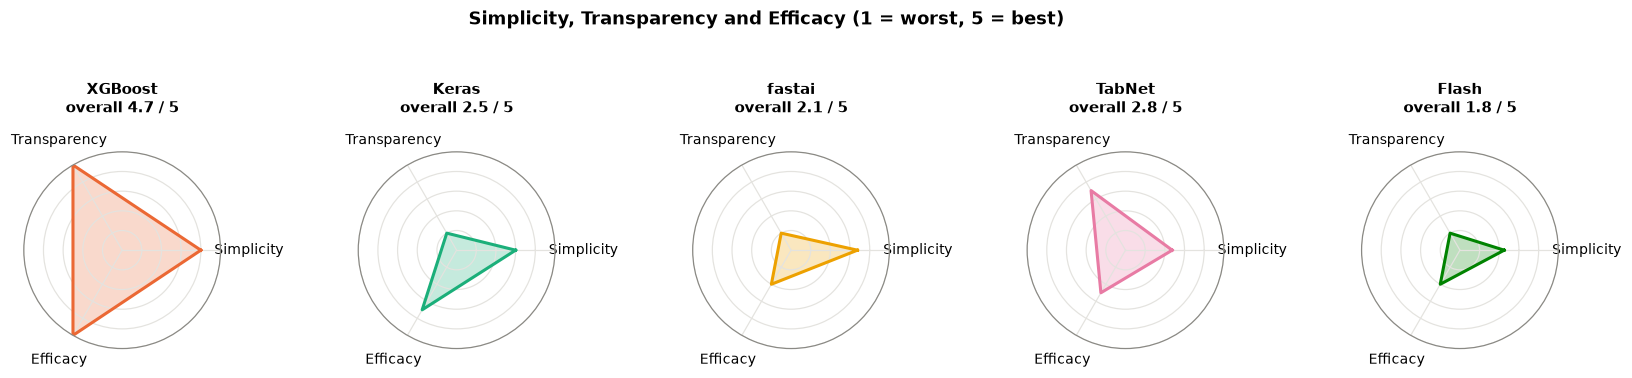

In [16]:
labels = ["Simplicity", "Transparency", "Efficacy"]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, 5, figsize=(18, 4), subplot_kw={"polar": True})
plt.subplots_adjust(wspace=0.7)
for ax, fw in zip(axes, FRAMEWORKS):
    values = scores.loc[fw, labels].tolist()
    values += values[:1]
    ax.plot(angles, values, color=plots.MODEL_COLORS[fw], linewidth=2)
    ax.fill(angles, values, color=plots.MODEL_COLORS[fw], alpha=0.25)
    ax.set_ylim(0, 5)
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_yticklabels(["", "", "", "", ""])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=9)
    ax.tick_params(axis="x", pad=8)
    ax.set_title(f"{fw}\noverall {scores.loc[fw, 'Overall (average)']:.1f} / 5", fontsize=10, pad=14)
fig.suptitle("Simplicity, Transparency and Efficacy (1 = worst, 5 = best)", fontweight="bold", y=1.04)
plots.save(fig, "09_radar")
plt.show()

**Observations**
- **XGBoost (4.7/5)** has the shortest code (5 lines) and is fast (0.8 s for the three models). It's the most transparent (gain and exact SHAP values, same result every run) and has the best results of the five frameworks.
- **TabNet (2.8)** is the second most transparent thanks to its attention masks. But it's the slowest (9.2 s per run), has the most hyperparameters (10), and the weakest results in experiment C.
- **Keras (2.5)** is easy to install, with a clear 13-line model and the second-best results, but it's a black box and changes with the seed.
- **fastai (2.1)** handles normalisation automatically and has `lr_find`, and it's quick. But it's a black box with weaker results.
- **Lightning Flash (1.8)** has short code, but it's archived: it needed a separate Python environment, old pinned versions and two missing dependencies, and it has an in-place data bug. It's also a black box.
- The linear regression baseline wasn't scored, but it would match XGBoost on transparency and beat it on simplicity and efficacy.

## 9. Conclusion

1. **The target matters more than the framework.** Predicting yield *levels*, as in the original case study, makes every model fail on 2023-2026, because yields reached levels never seen in training. Trees fail worst because they can't extrapolate. Predicting the *change* and removing the raw level inputs (experiment C) brings every model to within about 1.7 bp of the naive forecast.
2. **No model beats the naive "no change" forecast** in a statistically significant way. One-week-ahead moves in Treasury yields are close to unpredictable from public data, because markets price in information quickly. This matches earlier research, where a random walk is very hard to beat at short horizons (Diebold & Li, 2006).
3. **Simpler is better here.** Linear regression and XGBoost come closest to naive. The four neural networks are slightly worse and their results depend on the random seed.
4. **Framework ranking:** XGBoost first (simple, transparent, best results), then TabNet, Keras, fastai and Lightning Flash. For a real system we would use XGBoost or a linear model on the change target, always checked against the naive benchmark.
5. **Future work:** longer horizons (1-3 months), where economic data may help more; forecasting Nelson-Siegel factors; retraining regularly as new data arrives; and adding inflation data and Fed funds futures (market expectations of rate moves).